#### Loan Approval Prediction - Knn
Columns:
- Loan_ID
- Gender
- Married
- Dependents
- Education
- Self_Employed
- ApplicantIncome
- CoapplicantIncome
- LoanAmount
- Loan_Amount_Term
- Credit_History
- Property_Area
- Loan_Status

In [1]:
# import pakages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# load dataset
df = pd.read_csv('loan_prediction.csv')


In [3]:
df.shape, df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


((614, 13), None)

##### Data cleaning..


In [4]:
df.head() 

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [5]:
# remove useless column
df.drop(columns='Loan_ID',axis=1,inplace=True)

In [6]:
df.isnull().sum() 

Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [7]:
missing_cat_col = ['Gender', 'Married', 'Dependents', 'Self_Employed']
missing_num_col = ['LoanAmount','Loan_Amount_Term', 'Credit_History',]

for col in missing_cat_col:
    df[col] = df[col].fillna(df[col].mode()[0])

In [8]:
for col in missing_num_col:
    df[col] = df[col].fillna(df[col].median())

In [9]:
### Fix Data Types...
df['Dependents'] = df['Dependents'].str.replace('+','')
df['Dependents'] = df['Dependents'].astype('int64')

In [10]:
# standrixed text
object_col = df.select_dtypes(include=['object'])
for col in object_col:
    df[col] = df[col].str.lower()
df[col] = df[col].str.strip()

In [11]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,male,no,0,graduate,no,5849,0.0,128.0,360.0,1.0,urban,y
1,male,yes,1,graduate,no,4583,1508.0,128.0,360.0,1.0,rural,n
2,male,yes,0,graduate,yes,3000,0.0,66.0,360.0,1.0,urban,y
3,male,yes,0,not graduate,no,2583,2358.0,120.0,360.0,1.0,urban,y
4,male,no,0,graduate,no,6000,0.0,141.0,360.0,1.0,urban,y


In [12]:
# covert semiurban to urban for make it binary...
df['Property_Area'] = df['Property_Area'].replace('Semiurban', 'Urban')

##### EDA

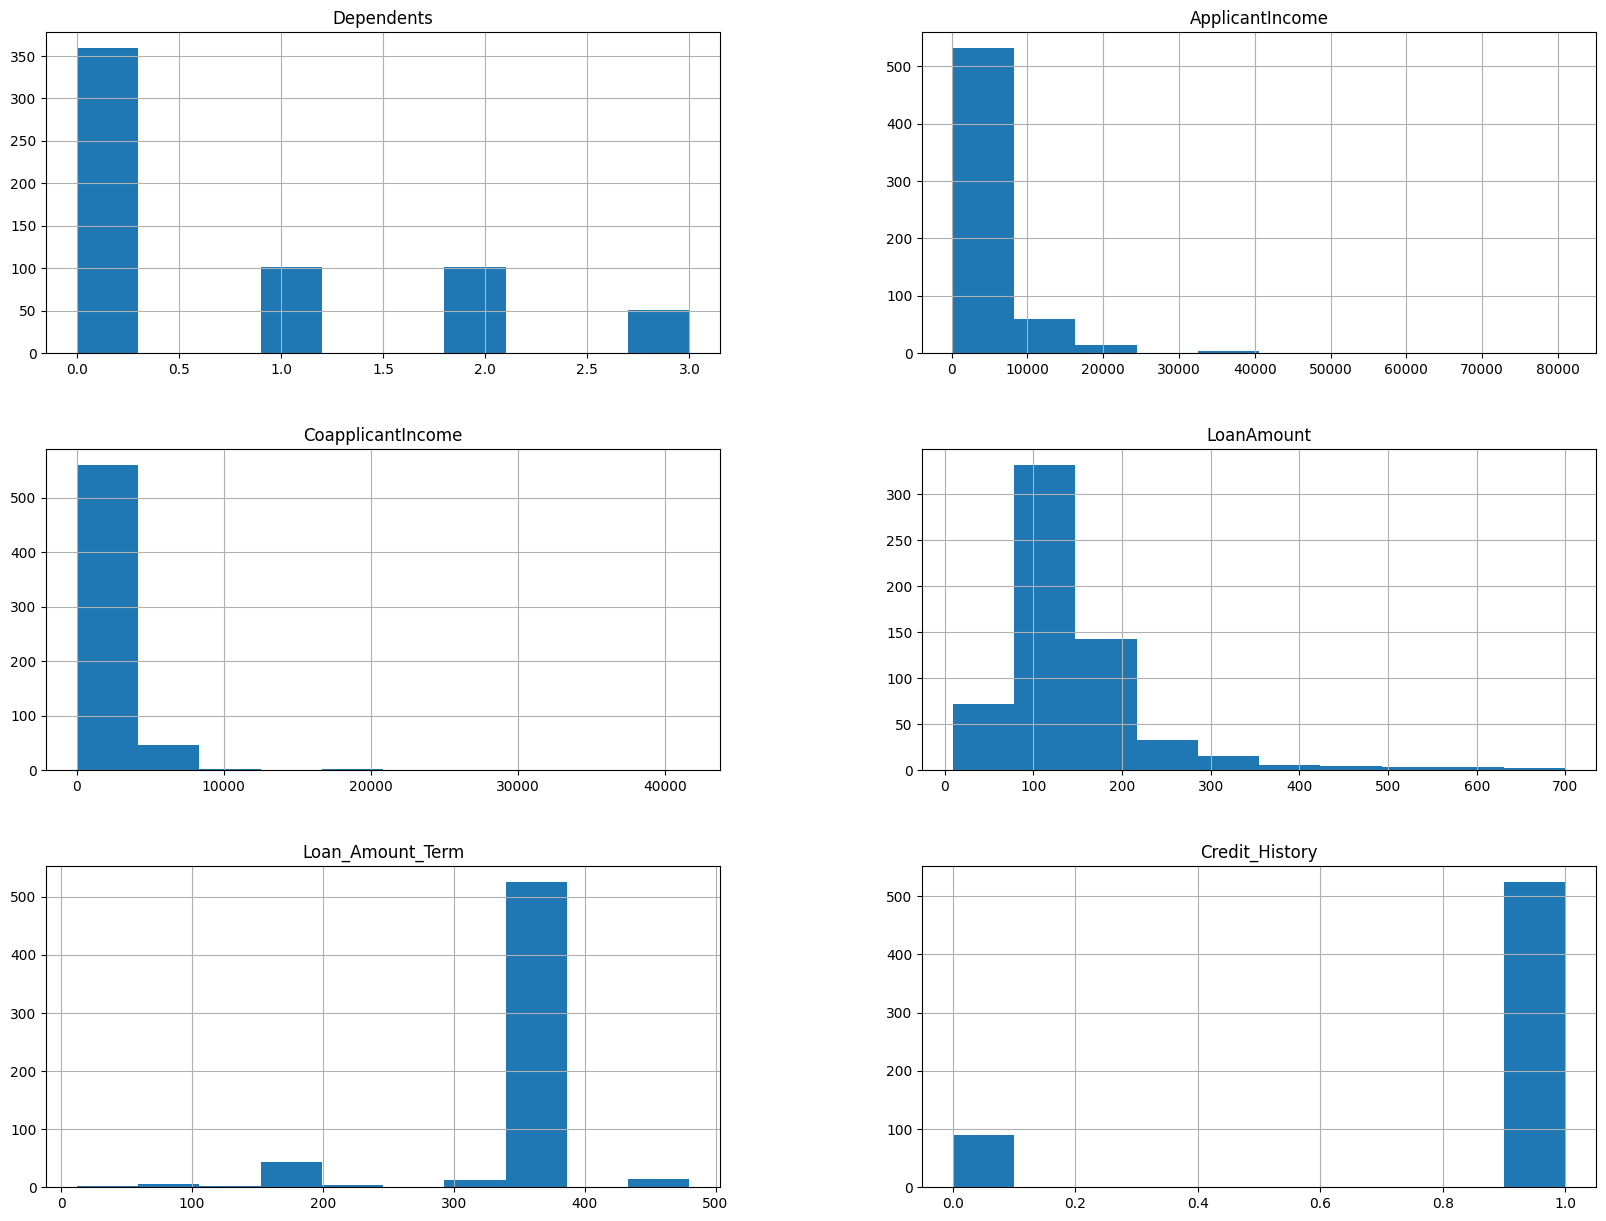

In [13]:
df.hist(bins=10,figsize=(20,15))
plt.show() 

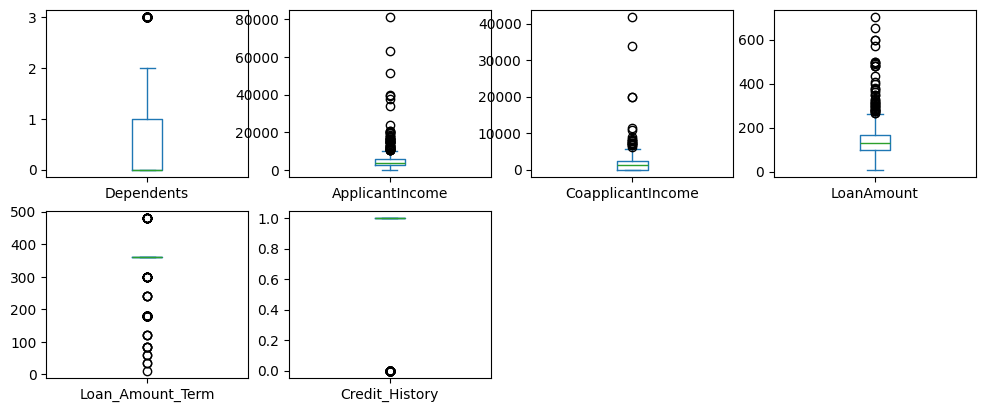

In [14]:
df.plot(kind='box', subplots=True, layout=(4,4), figsize=(12,10))
plt.show()

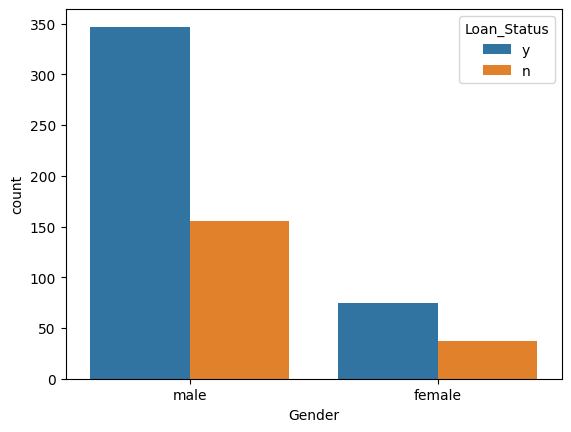

In [15]:
sns.countplot(x='Gender', hue='Loan_Status', data=df)
plt.show()

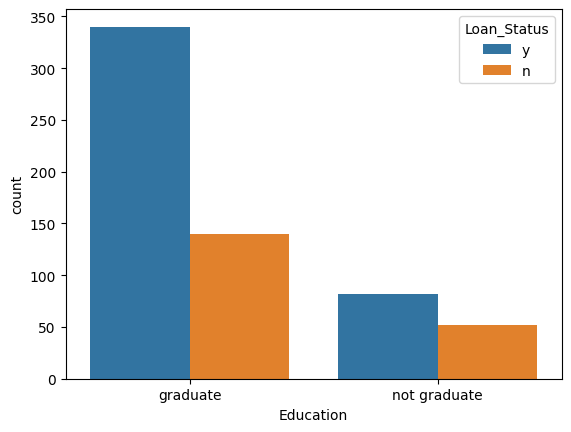

In [16]:
sns.countplot(x='Education', hue='Loan_Status', data=df)
plt.show()

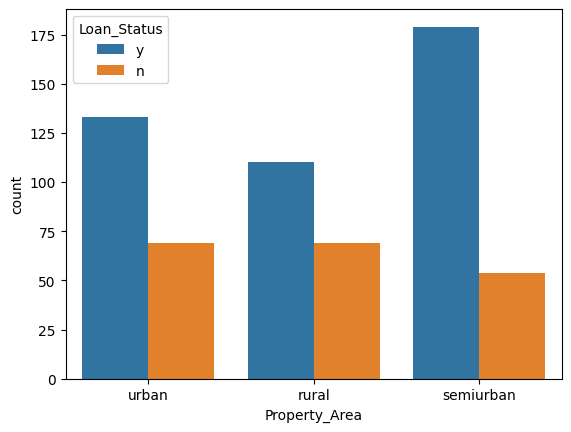

In [17]:
sns.countplot(x='Property_Area', hue='Loan_Status', data=df)
plt.show()

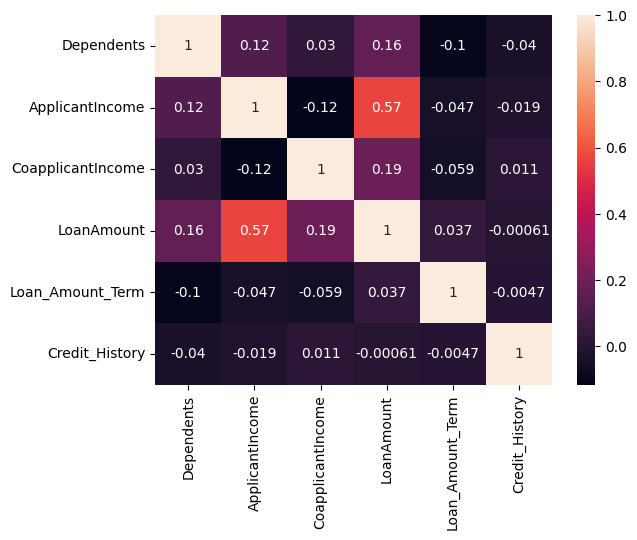

In [18]:
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

In [19]:
# encoding..
from sklearn.preprocessing import LabelEncoder
binary_col = ['Gender','Married','Education','Self_Employed','Property_Area','Loan_Status']
for col in binary_col: 
    encoder = LabelEncoder() 
    df[col] = encoder.fit_transform(df[col]) 

In [20]:
df.head() 

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,0,0,0,0,5849,0.0,128.0,360.0,1.0,2,1
1,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,0
2,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,2,1
3,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,2,1
4,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,2,1


##### Model traning - Knn

In [21]:
x = df.drop(columns='Loan_Status',axis=1)
y = df['Loan_Status']

In [22]:
# train test split
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.25,random_state=42) 


In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [24]:
print(y_train.value_counts()) 

Loan_Status
1    322
0    138
Name: count, dtype: int64


In [25]:
# model train
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier(n_neighbors=7,algorithm='auto')
model.fit(x_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",7
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [30]:
y_pred = model.predict(x_test)
y_pred

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0])

##### Evaluation

In [31]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix #type:ignore

accuracy = accuracy_score(y_pred,y_test)
print(f'accuracy: {accuracy*100} %')

matrix = confusion_matrix(y_pred,y_test)
print(f'Confusion matrix : \n{matrix}\n')

report = classification_report(y_pred,y_test)
print(f'Classification report: \n{report}')

accuracy: 76.62337662337663 %
Confusion matrix : 
[[22  4]
 [32 96]]

Classification report: 
              precision    recall  f1-score   support

           0       0.41      0.85      0.55        26
           1       0.96      0.75      0.84       128

    accuracy                           0.77       154
   macro avg       0.68      0.80      0.70       154
weighted avg       0.87      0.77      0.79       154



___

In [ ]:
# save in pkl
import joblib

joblib.dump({
    "model": model,
    "scaler": scaler,
}, "loan_model.pkl")

['loan_model.pkl']